# 🏦 Bank Marketing Term Deposit Predictor
## 📓 01. Exploratory Data Analysis & Baseline Benchmarks

**Course**: Neural Networks (AIE231)  
**Author / Owner**: Yousef Gamal (Tech Lead & Baseline/Analysis Engineer — Roles 1 & 3)  
**Dataset**: [UCI Bank Marketing (`bank-full.csv`)](https://archive.ics.uci.edu/dataset/222/bank+marketing) (`45,211` records, `16` input features)  
**Date**: November 2026  

---

### 🎯 Problem Formulation & Business Objective
Retail commercial banks routinely conduct direct telemarketing phone campaigns to promote fixed-term deposits (`y = 1`). Contacting uninterested clients wastes call-center capacity and risks client dissatisfaction (**False Positives**), whereas failing to reach an interested prospective depositor forfeits high-value deposit capital and customer lifetime value (**False Negatives**).

The engineering goal of this project is to construct a leak-free neural classification pipeline that reliably identifies prospective subscribers based strictly on **pre-call demographic and campaign indicators**.

#### Evaluation Metric Justification
Due to severe class skew (~88.3% *No* vs. ~11.7% *Yes*), naive **accuracy** is fundamentally misleading (a trivial model predicting *No* achieves 88.3% accuracy with 0.0 utility). The primary evaluation metrics are therefore:
1. **Positive-Class F1-Score**: Harmonic mean of positive precision and recall.
2. **Positive-Class Recall**: Ensuring prospective depositors are captured.
3. **PR-AUC (Precision-Recall Area Under Curve)**: Robust threshold-independent benchmark on imbalanced tabular data.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## 1. Data Ingestion & Schema Inspection

In [2]:
data_path = os.path.join("..", "data", "raw", "bank-full.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "raw", "bank-full.csv")

df = pd.read_csv(data_path, sep=";")
print(f"Loaded Bank Marketing dataset: {df.shape[0]:,} rows, {df.shape[1]} columns.")
print(f"Exact duplicate rows: {df.duplicated().sum()}")
df.head()

Loaded Bank Marketing dataset: 45,211 rows, 17 columns.
Exact duplicate rows: 0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
print("Column Data Types and Non-Null Counts:")
df.info()

Column Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


## 2. Target Variable Analysis (`y`)
We examine the subscription distribution to quantify class imbalance.

Target Class Distribution:
  'no': 39,922 (88.30%)
  'yes': 5,289 (11.70%)


C:\Users\youssef\AppData\Local\Temp\ipykernel_13028\1235277065.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="y", ax=ax[0], palette=["#4A90E2", "#50E3C2"])


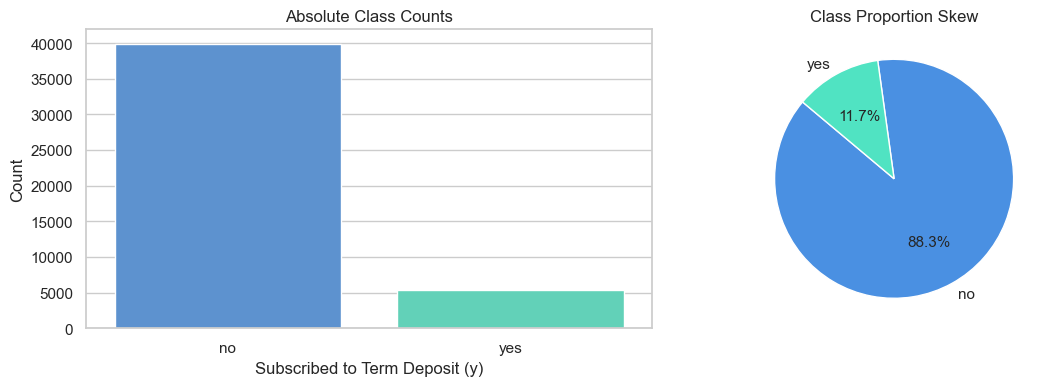

In [4]:
target_counts = df["y"].value_counts()
target_pcts = df["y"].value_counts(normalize=True) * 100

print("Target Class Distribution:")
for label, count in target_counts.items():
    print(f"  '{label}': {count:,} ({target_pcts[label]:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="y", ax=ax[0], palette=["#4A90E2", "#50E3C2"])
ax[0].set_title("Absolute Class Counts")
ax[0].set_xlabel("Subscribed to Term Deposit (y)")
ax[0].set_ylabel("Count")

ax[1].pie(target_counts, labels=target_counts.index, autopct="%1.1f%%", startangle=140, colors=["#4A90E2", "#50E3C2"])
ax[1].set_title("Class Proportion Skew")
plt.tight_layout()
plt.show()

**Finding**: Severe class skew (~88.3% `no` vs. ~11.7% `yes`, approximately 7.55:1 ratio).  
**Decision**: Accuracy cannot be used as the optimization criterion. We must use class-weighted loss, stratified splitting, and track positive-class F1, Recall, and PR-AUC.

## 3. Critical Target Leakage Analysis: The `duration` Column

> **UCI Documentation Warning**:  
> *"duration: last contact duration, in seconds... this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model."*

Let us empirically verify why retaining `duration` constitutes severe data leakage.

C:\Users\youssef\AppData\Local\Temp\ipykernel_13028\3569116473.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="y", y="duration", palette=["#4A90E2", "#50E3C2"], showfliers=False)


Duration Statistics by Target Outcome (seconds):
       count        mean         std  min    25%    50%    75%     max
y                                                                     
no   39922.0  221.182806  207.383237  0.0   95.0  164.0  279.0  4918.0
yes   5289.0  537.294574  392.525262  8.0  244.0  426.0  725.0  3881.0


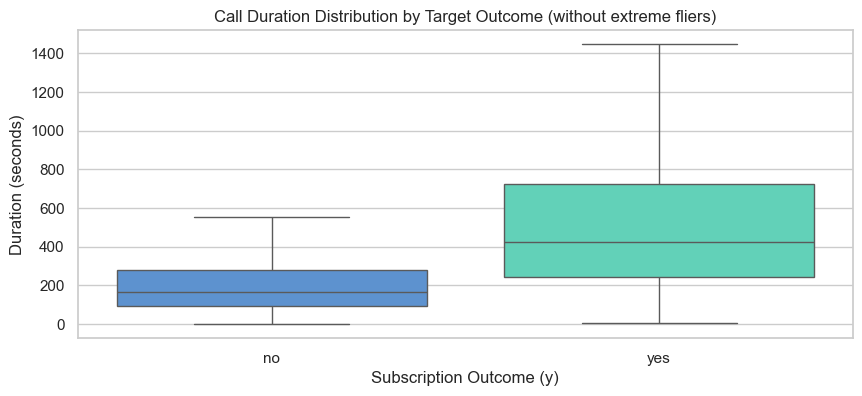

In [5]:
print("Duration Statistics by Target Outcome (seconds):")
print(df.groupby("y")["duration"].describe())

plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="y", y="duration", palette=["#4A90E2", "#50E3C2"], showfliers=False)
plt.title("Call Duration Distribution by Target Outcome (without extreme fliers)")
plt.xlabel("Subscription Outcome (y)")
plt.ylabel("Duration (seconds)")
plt.show()

**Finding**: Subscribed clients have a median call duration over 2.5× longer than non-subscribed clients. Call duration is only known *after* the call finishes, making it unusable for pre-call targeting.  
**Decision**: Drop `duration` immediately from all feature sets to enforce strict zero-leakage discipline.

## 4. Missing Values & The `'unknown'` Label
In this dataset, missing values are represented as string `'unknown'` entries rather than `NaN`.

In [6]:
unknown_counts = {}
for col in df.select_dtypes(include=["object"]).columns:
    if col == "y":
        continue
    cnt = (df[col] == "unknown").sum()
    pct = (cnt / len(df)) * 100
    if cnt > 0:
        unknown_counts[col] = (cnt, pct)

print("Columns with 'unknown' values:")
unknown_df = pd.DataFrame([
    {"Feature": col, "Count": cnt, "Percentage (%)": f"{pct:.2f}%"}
    for col, (cnt, pct) in sorted(unknown_counts.items(), key=lambda x: x[1][0], reverse=True)
])
unknown_df

Columns with 'unknown' values:


,Feature,Count,Percentage (%)
0,poutcome,36959,81.75%
1,contact,13020,28.80%
2,education,1857,4.11%
3,job,288,0.64%


**Finding**: `poutcome` (~81.7% `'unknown'` for never contacted), `contact` (~28.8%), `education` (~4.1%), and `job` (~0.6%) contain `'unknown'` entries.  
**Decision**: Preserve `'unknown'` as an explicit valid category during one-hot encoding rather than dropping rows.

## 5. Numerical Features, Outliers & `pdays = -1` Sentinel

In [7]:
num_cols = ["age", "balance", "day", "campaign", "pdays", "previous"]
print(f"pdays == -1 (never contacted) count: {(df['pdays'] == -1).sum():,} ({(df['pdays'] == -1).mean() * 100:.2f}%)")
df[num_cols].describe().T

pdays == -1 (never contacted) count: 36,954 (81.74%)


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


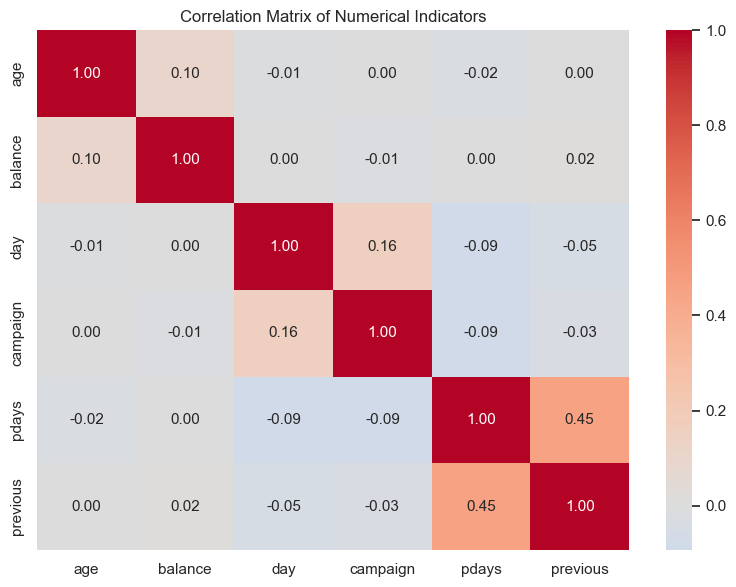

In [8]:
plt.figure(figsize=(8, 6))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=True)
plt.title("Correlation Matrix of Numerical Indicators")
plt.tight_layout()
plt.show()

**Finding**: `pdays = -1` is a sentinel meaning "never previously contacted" (~81.7% of rows), and `balance`, `campaign`, `previous`, and `pdays` are strongly right-skewed with large outliers.  
**Decision**: Convert `pdays == -1` into a binary `previously_contacted` indicator + `0`, apply signed `log1p` to skewed numeric columns, and apply `StandardScaler` strictly on the training split.

## 6. Categorical Feature Conversion Rates

C:\Users\youssef\AppData\Local\Temp\ipykernel_13028\3584825913.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conversion.index, y=conversion.values, ax=axes[idx], palette="viridis")
C:\Users\youssef\AppData\Local\Temp\ipykernel_13028\3584825913.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conversion.index, y=conversion.values, ax=axes[idx], palette="viridis")
C:\Users\youssef\AppData\Local\Temp\ipykernel_13028\3584825913.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conversion.index, y=conversion.values, ax=axes[idx],

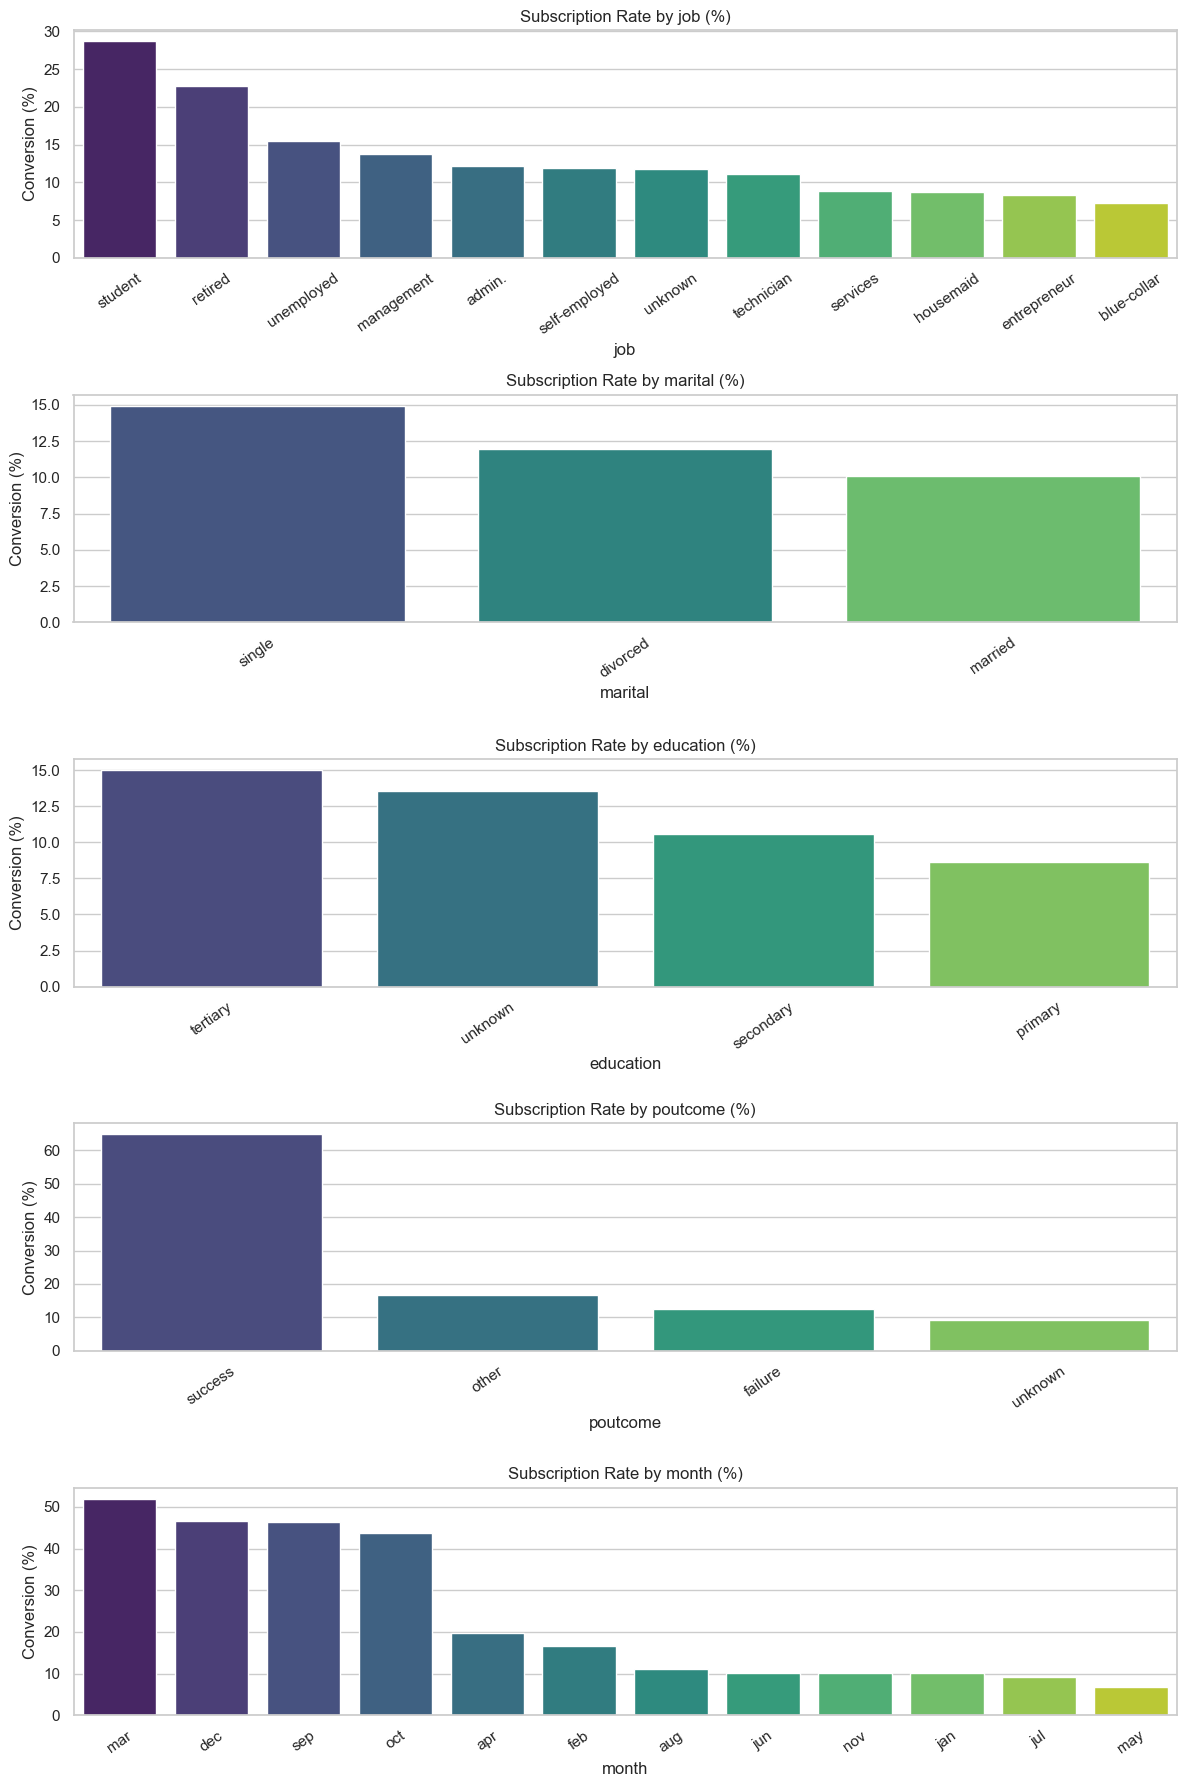

In [9]:
cat_cols = ["job", "marital", "education", "poutcome", "month"]
fig, axes = plt.subplots(len(cat_cols), 1, figsize=(12, 18))

for idx, col in enumerate(cat_cols):
    conversion = df.groupby(col)["y"].apply(lambda x: (x == "yes").mean() * 100).sort_values(ascending=False)
    sns.barplot(x=conversion.index, y=conversion.values, ax=axes[idx], palette="viridis")
    axes[idx].set_title(f"Subscription Rate by {col} (%)")
    axes[idx].set_ylabel("Conversion (%)")
    axes[idx].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

**Finding**: `poutcome = 'success'` exhibits the highest conversion rate (~64.7%), and students/retired clients convert at much higher rates than blue-collar workers.  
**Decision**: One-hot encode all categorical columns so the MLP layers can learn non-linear feature interactions.

## 7. Leak-Free Preprocessing Pipeline & Baseline Benchmarks
We use the modular pipeline in `src/data.py` (stratified 70/15/15 split, `duration` dropped, train-only `StandardScaler` + `OneHotEncoder`) and evaluate the two mandated baselines:
1. **Trivial Baseline**: Majority-class prediction.
2. **Simple Learned Baseline**: Logistic Regression with balanced class weighting.

In [10]:
import sys
sys.path.insert(0, "..")
from src.data import prepare_data

d = prepare_data(save=False)
X_train, y_train = d.X_train, d.y_train
X_val, y_val = d.X_val, d.y_val
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Input dim: {X_train.shape[1]}")

# Baseline 1: Trivial Baseline (Majority Class)
y_val_trivial = np.zeros_like(y_val)
trivial_metrics = {
    "Model": "1. Trivial Baseline (Majority Class)",
    "Accuracy": accuracy_score(y_val, y_val_trivial),
    "Positive Precision": precision_score(y_val, y_val_trivial, zero_division=0),
    "Positive Recall": recall_score(y_val, y_val_trivial, zero_division=0),
    "Positive F1-Score": f1_score(y_val, y_val_trivial, zero_division=0),
    "ROC-AUC": 0.5,
    "PR-AUC": float(y_val.mean()),
}

# Baseline 2: Logistic Regression (Balanced Class Weights)
lr_clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
lr_clf.fit(X_train, y_train)

y_val_lr_pred = lr_clf.predict(X_val)
y_val_lr_prob = lr_clf.predict_proba(X_val)[:, 1]

learned_metrics = {
    "Model": "2. Learned Baseline (Logistic Regression)",
    "Accuracy": accuracy_score(y_val, y_val_lr_pred),
    "Positive Precision": precision_score(y_val, y_val_lr_pred, zero_division=0),
    "Positive Recall": recall_score(y_val, y_val_lr_pred, zero_division=0),
    "Positive F1-Score": f1_score(y_val, y_val_lr_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_val_lr_prob),
    "PR-AUC": average_precision_score(y_val, y_val_lr_prob),
}

results_df = pd.DataFrame([trivial_metrics, learned_metrics])
results_df.set_index("Model").round(4)

Train: (31647, 51), Val: (6782, 51), Input dim: 51


,Accuracy,Positive Precision,Positive Recall,Positive F1-Score,ROC-AUC,PR-AUC
Model,,,,,,
1. Trivial Baseline (Majority Class),0.8829,0.0000,0.0000,0.0000,0.5000,0.1171
2. Learned Baseline (Logistic Regression),0.7539,0.2686,0.6398,0.3784,0.7755,0.4224


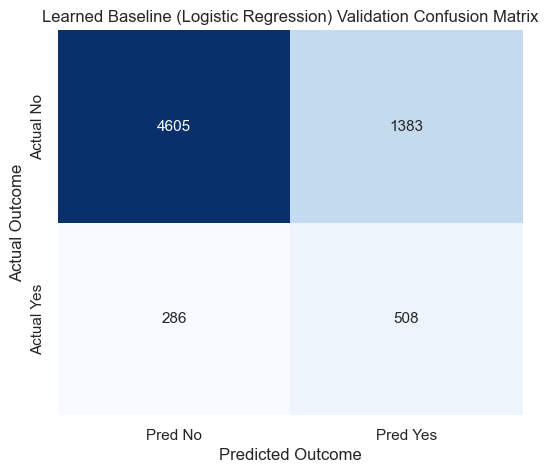

In [11]:
cm = confusion_matrix(y_val, y_val_lr_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"])
plt.title("Learned Baseline (Logistic Regression) Validation Confusion Matrix")
plt.ylabel("Actual Outcome")
plt.xlabel("Predicted Outcome")
plt.show()

## 8. Summary of EDA Findings & Modeling Decisions

| # | Empirical Finding in EDA | Architectural / Preprocessing Decision | Responsible Role |
| :--- | :--- | :--- | :--- |
| **1** | Severe class imbalance: ~88.3% *No* vs. ~11.7% *Yes*. | Use balanced class weighting in loss; optimize for Positive F1, Recall & PR-AUC. | Role 2 (Data) & Role 5 (Train) |
| **2** | `duration` shows artificial correlation with target but is unknown pre-call. | Drop `duration` entirely prior to any modeling to prevent target leakage. | Role 2 (Data) |
| **3** | `'unknown'` entries in categorical variables (`poutcome`, `contact`, `education`). | Preserve `'unknown'` as an explicit one-hot encoded category rather than dropping rows. | Role 2 (Data) |
| **4** | `pdays = -1` sentinel & heavy right skew in `balance`, `campaign`, `previous`. | Add `previously_contacted` flag, apply signed `log1p`, then `StandardScaler` on train only. | Role 2 (Data) |
| **5** | Learned Baseline achieves Positive F1 ~ 0.38 and Recall ~ 0.64. | Neural models (Model A, B, C) must beat Logistic Regression on F1 & PR-AUC. | Role 1 & 3 (Yousef) & Role 4 (Jessica) |
| **6** | Input dimension after one-hot encoding is $D = 51$. | Model A uses 32 hidden units; Model B uses $128 \rightarrow 64 \rightarrow 32$ with Dropout (0.3). | Role 4 (Model Architect) |